# Chapitre 3 - Exercices 3.1 à 3.6

Ce notebook traite les six premiers exercices du chapitre 3, centrés sur les métriques
de modélisation du langage et l'évaluation exacte :

- **3.1** : bornes de l'entropie et langue du carré non uniforme (démonstration et calcul) ;
- **3.2** : conversions entre entropie croisée, BPC, BPB et perplexité, sur le tableau 3-1
  du livre puis sur de vrais modèles ;
- **3.3** : minimiser l'entropie croisée, c'est faire du maximum de vraisemblance ; KL
  directe contre KL inverse ;
- **3.4** : contamination sous paraphrase, et test de complétion de préfixe (mini-lab) ;
- **3.5** : pass@k, calculs à la main, variance de l'estimateur et significativité ;
- **3.6** : construire un vérificateur de réponses courtes plus robuste que la
  correspondance exacte (mini-lab).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import ch03_evaluation as ev
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
rng = np.random.default_rng(0)
llm.seed_everything(0)
pd.set_option("display.precision", 4)
QWEN_BASE = "Qwen/Qwen2.5-0.5B"

## Exercice 3.1 : Bornes de l'entropie et langue du carré

**Énoncé.**

1. Montrer que pour toute loi $P$ sur un vocabulaire de $V$ symboles,
   $0 \le H(P) \le \log_2 V$, et préciser les cas d'égalité.
2. Dans la langue (b) du livre (quatre tokens *haut-gauche*, *haut-droite*, *bas-gauche*,
   *bas-droite*), on suppose que les positions du haut sont trois fois plus fréquentes que
   celles du bas, et que gauche et droite sont équiprobables. Calculer l'entropie et la
   perplexité de cette langue.
3. Montrer que si deux variables $X$ (haut/bas) et $Y$ (gauche/droite) sont
   indépendantes, $H(X, Y) = H(X) + H(Y)$, et vérifier le résultat de la question 2.

**Rappels.** Entropie $H(P) = -\sum_x P(x)\log_2 P(x)$ ; entropie croisée
$H(P, Q) = H(P) + D_{KL}(P\|Q)$ avec $D_{KL} \ge 0$ (inégalité de Gibbs) ; perplexité
$2^{H}$ (section *Entropy* et *Perplexity*, cours 1, sections 2 à 4).

**Solution.**

*1. Borne inférieure.* Chaque terme $-P(x)\log_2 P(x)$ est positif car $0 \le P(x) \le 1$.
Il est nul si et seulement si $P(x) \in \{0, 1\}$ : $H(P) = 0$ ssi $P$ est un Dirac (un
seul symbole possible, aucune surprise).

*Borne supérieure.* Prenons $U$ la loi uniforme sur les $V$ symboles. Alors
$H(P, U) = -\sum_x P(x)\log_2 \frac1V = \log_2 V$. Par la décomposition
$H(P, U) = H(P) + D_{KL}(P\|U)$ et $D_{KL} \ge 0$ :
$H(P) \le \log_2 V$, avec égalité ssi $D_{KL}(P\|U) = 0$, c'est-à-dire $P = U$.

*2.* $P(\text{haut}) = 3/4$, $P(\text{bas}) = 1/4$, et chaque moitié se partage
également entre gauche et droite : les quatre probabilités sont
$(3/8, 3/8, 1/8, 1/8)$. Donc
$$H = -2\cdot\tfrac38\log_2\tfrac38 - 2\cdot\tfrac18\log_2\tfrac18 = \tfrac34\log_2\tfrac83 + \tfrac14\cdot 3 \approx 0{,}811 + 1 = 1{,}811 \text{ bit},$$
et la perplexité vaut $2^{1{,}811} \approx 3{,}51$ : un peu moins que les 4 options de la
version uniforme.

*3.* Si $P(x, y) = P(x)P(y)$, alors
$-\log P(x,y) = -\log P(x) - \log P(y)$ ; en prenant l'espérance,
$H(X, Y) = H(X) + H(Y)$. Ici $H(X) = H(3/4, 1/4) \approx 0{,}811$ et $H(Y) = 1$ : on
retrouve $1{,}811$ bit. L'entropie (comme la log-vraisemblance) est **additive** sur des
événements indépendants, ce qui justifie de sommer les surprises des tokens. $\blacksquare$

**Vérification numérique** : les calculs, puis l'entropie de 2 000 lois aléatoires
(Dirichlet) sur $V$ symboles, toujours sous la borne $\log_2 V$.

H = 1.8113 bit ; PPL = 3.510 ; H(X) + H(Y) = 1.8113


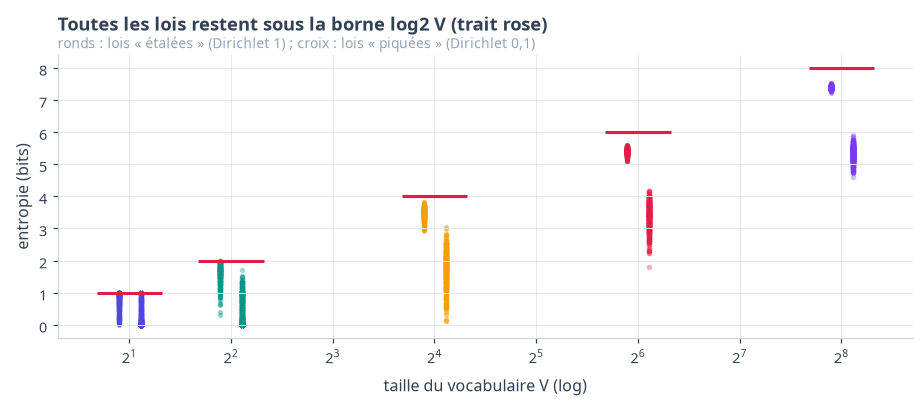

In [2]:
p4 = np.array([3, 3, 1, 1]) / 8
print(f"H = {ev.entropy(p4):.4f} bit ; PPL = {2 ** ev.entropy(p4):.3f} ; "
      f"H(X) + H(Y) = {ev.entropy([0.75, 0.25]) + ev.entropy([0.5, 0.5]):.4f}")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for V, c in zip([2, 4, 16, 64, 256], COLORS):
    for alpha, mk in [(1.0, "o"), (0.1, "x")]:
        h = [ev.entropy(rng.dirichlet(np.full(V, alpha))) for _ in range(400)]
        ax.scatter(np.full(400, V) * (1.08 if alpha == 0.1 else 0.93), h, s=6, color=c, alpha=0.35, marker=mk)
    ax.hlines(math.log2(V), V * 0.8, V * 1.25, color=ROSE, lw=2)
ax.set_xscale("log", base=2); ax.set_xlabel("taille du vocabulaire V (log)"); ax.set_ylabel("entropie (bits)")
ax.set_title("Toutes les lois restent sous la borne log2 V (trait rose)")
subtitle(ax, "ronds : lois « étalées » (Dirichlet 1) ; croix : lois « piquées » (Dirichlet 0,1)")
plt.tight_layout(); plt.show()

> **À retenir.** $0 \le H(P) \le \log_2 V$ : l'entropie est nulle pour une langue
> parfaitement prévisible, maximale pour une langue uniforme, et additive sur des
> composantes indépendantes.

## Exercice 3.2 : Conversions entre CE, BPC, BPB et perplexité

**Énoncé.**

1. Le tableau 3-1 du livre indique pour GPT-2 (1 542 M paramètres) un BPB de 0,93 sur
   enwik8 et un BPC de 0,98 sur text8. Quel taux de compression le premier chiffre
   représente-t-il ? Quelle perplexité par caractère le second ?
2. Un modèle annonce une perplexité de 12 par token sur un corpus anglais (ASCII,
   1 octet par caractère, 4,3 caractères par token), et de 20 par token sur un corpus
   français (UTF-8, 1,04 octet par caractère en moyenne, 3,4 caractères par token). Sur
   quel corpus est-il le meilleur « compresseur » ?
3. Vérifier sur GPT-2 et Qwen2.5 l'identité
   $\mathrm{BPB} = \log_2(\mathrm{PPL}) \cdot N / B$ ($N$ tokens, $B$ octets) sur un texte
   anglais et un texte français.

**Rappels.** $\mathrm{CE}_{\text{bits}} = \log_2 \mathrm{PPL}$,
$\mathrm{BPC} = \mathrm{CE}_{\text{bits}}/(\text{caractères par token})$,
$\mathrm{BPB} = \mathrm{BPC}/(\text{octets par caractère})$ (sections
*Bits-per-Character and Bits-per-Byte* et *Perplexity*, cours 1 section 4).

**Solution.**

*1.* Un BPB de 0,93 signifie 0,93 bit par octet de 8 bits : le texte compressé occupe
$0{,}93/8 \approx 11{,}6\,\%$ de sa taille, un taux de compression d'environ 8,6 (gzip
fait environ 3 sur ce type de texte). Un BPC de 0,98 donne une perplexité par caractère
$2^{0{,}98} \approx 1{,}97$ : le modèle hésite en moyenne entre deux caractères à peine.

*2.* Anglais : $\log_2 12 = 3{,}585$ bits/token, soit $3{,}585/4{,}3 = 0{,}834$ BPC et
autant de BPB. Français : $\log_2 20 = 4{,}322$ bits/token, $4{,}322/3{,}4 = 1{,}271$
BPC, $1{,}271/1{,}04 = 1{,}222$ BPB. Le modèle compresse mieux l'anglais (0,83 contre
1,22 bit par octet). Comparer « 12 » et « 20 » aurait été trompeur dans l'autre sens
aussi : les tokens n'ont pas la même longueur.

*3.* En notant $L$ la NLL totale, $\log_2 \mathrm{PPL} = L/(N\ln 2)$ et
$\mathrm{BPB} = L/(B\ln 2)$, d'où l'identité. $\blacksquare$

In [3]:
def conv(ppl, chars_per_tok, bytes_per_char):
    ce = math.log2(ppl)
    bpc = ce / chars_per_tok
    return dict(ce_bits=ce, bpc=bpc, bpb=bpc / bytes_per_char, compression=8 / (bpc / bytes_per_char))


pd.DataFrame({"anglais (PPL 12)": conv(12, 4.3, 1.0), "français (PPL 20)": conv(20, 3.4, 1.04)}).T

,ce_bits,bpc,bpb,compression
anglais (PPL 12),3.5850,0.8337,0.8337,9.5956
français (PPL 20),4.3219,1.2712,1.2223,6.5452


**Vérification** de l'identité sur de vrais modèles.

In [4]:
textes = {"anglais": ev.FRESH_TEXTS["Récit (inédit)"],
          "français": ("Chaque automne, la petite ville côtière organise une fête pour célébrer le retour des bateaux "
                       "de pêche ; les familles se retrouvent sur le port et partagent un long repas.")}
rows = []
for langue, t in textes.items():
    for mod, mid in [("GPT-2", llm.BASE), ("Qwen2.5 base", QWEN_BASE)]:
        m = ev.text_metrics(t, mid)
        rows.append(dict(texte=langue, modele=mod, N=m.n_tokens, B=m.n_bytes, ppl=m.ppl, bpb=m.bpb,
                         identite=math.log2(m.ppl) * m.n_tokens / m.n_bytes))
V32 = pd.DataFrame(rows)
V32

,texte,modele,N,B,ppl,bpb,identite
0,anglais,GPT-2,52,263,62.3482,1.1789,1.1789
1,anglais,Qwen2.5 base,53,263,47.5328,1.1226,1.1226
2,français,GPT-2,55,177,172.6218,2.3092,2.3092
3,français,Qwen2.5 base,48,177,13.8814,1.0292,1.0292


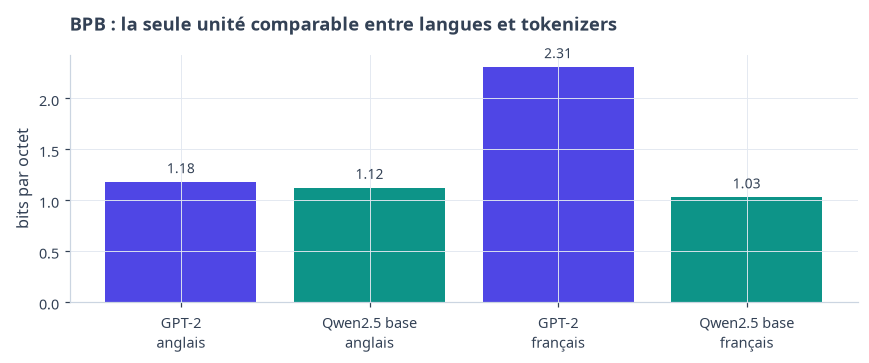

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
lab = [f"{r.modele}\n{r.texte}" for r in V32.itertuples()]
ax.bar(lab, V32.bpb, color=[INDIGO, TEAL, INDIGO, TEAL])
annotate_bars(ax, "{:.2f}")
ax.set_ylabel("bits par octet"); ax.set_title("BPB : la seule unité comparable entre langues et tokenizers")
plt.tight_layout(); plt.show()

Les colonnes `bpb` et `identite` coïncident. GPT-2 et Qwen ont des BPB voisins sur
l'anglais ; sur le français, GPT-2 (entraîné quasi uniquement en anglais) s'effondre.

> **À retenir.** Pour comparer des modèles ou des corpus, convertir en bits par octet.
> Une perplexité par token n'est qu'une étape de calcul, liée au tokenizer.

## Exercice 3.3 : Entropie croisée, maximum de vraisemblance, KL directe et inverse

**Énoncé.**

1. On observe $N$ tokens tirés d'un vocabulaire de $V$ symboles, avec $n_v$ occurrences
   du symbole $v$. Montrer que le modèle catégoriel $q$ qui minimise l'entropie croisée
   empirique $-\frac1N\sum_v n_v \log q_v$ est $q_v = n_v / N$.
2. On paramètre $q = \mathrm{softmax}(z)$. Montrer que le gradient de l'entropie croisée
   par rapport à $z$ vaut $q - \hat p$ ($\hat p$ : fréquences empiriques), et le vérifier
   par une descente de gradient.
3. On approche une loi bimodale $P$ par une loi normale $Q$. Comparer la loi obtenue en
   minimisant $D_{KL}(P\|Q)$ (ce que fait l'entraînement par entropie croisée) et en
   minimisant $D_{KL}(Q\|P)$.

**Rappels.** $H(P, Q) = H(P) + D_{KL}(P\|Q)$ : à $P$ fixée, minimiser l'entropie croisée
en $Q$ revient à minimiser $D_{KL}(P\|Q)$ (section *Cross Entropy*, cours 1 section 3).
Softmax : $q_v = e^{z_v}/\sum_u e^{z_u}$.

**Solution.**

*1.* On minimise $f(q) = -\sum_v n_v\log q_v$ sous la contrainte $\sum_v q_v = 1$.
Lagrangien : $\mathcal L = -\sum_v n_v\log q_v + \lambda(\sum_v q_v - 1)$. En annulant
$\partial\mathcal L/\partial q_v = -n_v/q_v + \lambda$, on obtient $q_v = n_v/\lambda$,
et la contrainte donne $\lambda = N$. La fonction étant convexe, c'est le minimum :
**le modèle d'entropie croisée minimale est l'estimateur du maximum de vraisemblance**
(les fréquences). Pour un réseau de neurones, le principe est le même, sous la
contrainte de la paramétrisation.

*2.* $\mathrm{CE}(z) = -\sum_v \hat p_v \log q_v = -\sum_v \hat p_v z_v + \log\sum_u e^{z_u}$.
Donc $\partial \mathrm{CE}/\partial z_v = -\hat p_v + e^{z_v}/\sum_u e^{z_u} = q_v - \hat p_v$.
C'est le célèbre gradient « prédiction moins cible » de la couche de sortie d'un modèle
de langage.

*3.* Pour une normale, minimiser $D_{KL}(P\|Q)$ revient à égaler moyenne et variance de
$P$ (« moment matching ») : $Q$ **couvre** les deux modes, quitte à mettre de la masse
entre eux. Minimiser $D_{KL}(Q\|P) = \mathbb E_Q[\log Q - \log P]$ pénalise fortement
toute masse de $Q$ là où $P$ est faible : $Q$ **choisit un mode**. $\blacksquare$

In [6]:
# Questions 1 et 2 : descente de gradient sur les logits
comptes = np.array([50, 30, 15, 4, 1])
p_hat = comptes / comptes.sum()
z = np.zeros(5)
traj = []
for t in range(300):
    q = llm.softmax(z)
    traj.append(ev.cross_entropy(p_hat, q))
    z -= 1.0 * (q - p_hat)
q_final = llm.softmax(z)
print("fréquences :", p_hat.round(4), "\nsoftmax(z) :", q_final.round(4))
eps = 1e-6
g_num = np.array([(ev.cross_entropy(p_hat, llm.softmax(z + eps * np.eye(5)[v]), base=math.e) -
                   ev.cross_entropy(p_hat, llm.softmax(z - eps * np.eye(5)[v]), base=math.e)) / (2 * eps) for v in range(5)])
print("gradient numérique :", g_num.round(6), " | q - p_hat :", (llm.softmax(z) - p_hat).round(6))

fréquences : [0.5  0.3  0.15 0.04 0.01] 
softmax(z) : [0.4999 0.2999 0.1499 0.0399 0.0102]
gradient numérique : [-5.00e-05 -5.10e-05 -5.40e-05 -7.20e-05  2.27e-04]  | q - p_hat : [-5.00e-05 -5.10e-05 -5.40e-05 -7.20e-05  2.27e-04]


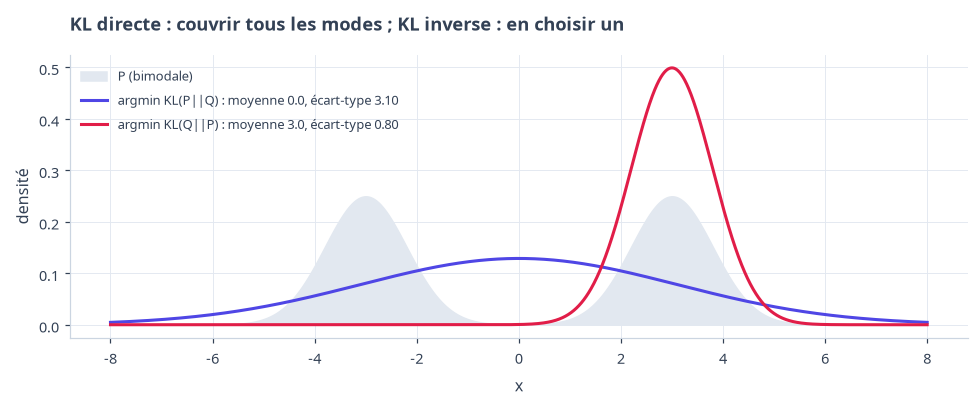

In [7]:
# Question 3 : KL directe contre KL inverse sur une grille
x = np.linspace(-8, 8, 2001)
dx = x[1] - x[0]
normal = lambda m, s: np.exp(-0.5 * ((x - m) / s) ** 2) / (s * np.sqrt(2 * np.pi))
P = 0.5 * normal(-3, 0.8) + 0.5 * normal(3, 0.8)


def kl(a, b):
    m = a > 1e-300
    return float(np.sum(a[m] * (np.log(a[m]) - np.log(np.maximum(b[m], 1e-300)))) * dx)


grille = [(m, s) for m in np.linspace(-4, 4, 81) for s in np.linspace(0.3, 4.5, 85)]
fwd = min(grille, key=lambda g: kl(P, normal(*g)))
rev = min(grille, key=lambda g: kl(normal(*g), P))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(x, P, color=LIGHT[SLATE], label="P (bimodale)")
ax.plot(x, normal(*fwd), color=INDIGO, label=f"argmin KL(P||Q) : moyenne {fwd[0]:.1f}, écart-type {fwd[1]:.2f}")
ax.plot(x, normal(*rev), color=ROSE, label=f"argmin KL(Q||P) : moyenne {rev[0]:.1f}, écart-type {rev[1]:.2f}")
ax.set_xlabel("x"); ax.set_ylabel("densité")
ax.set_title("KL directe : couvrir tous les modes ; KL inverse : en choisir un")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()

La descente de gradient retrouve les fréquences empiriques et le gradient numérique
coïncide avec $q - \hat p$. L'expérience bimodale illustre pourquoi un modèle pré-entraîné
par entropie croisée (KL directe) tend à **couvrir** toute la diversité des données,
alors que des objectifs de type KL inverse, que l'on retrouve dans certaines méthodes
d'alignement, favorisent des distributions plus **concentrées**. C'est une intuition
(pas une démonstration) de l'« effondrement de l'entropie » après post-entraînement
évoqué par le livre et mesuré au cours 1.

> **À retenir.** Minimiser l'entropie croisée = maximiser la vraisemblance = minimiser
> $D_{KL}(P\|Q)$ ; le gradient en sortie est « prédiction moins cible ». La KL directe
> couvre les modes, la KL inverse les sélectionne.